<a href="https://colab.research.google.com/github/GauriRaut58/Gauri-/blob/main/LAB_2_ML_C_52_GAURI_RAUT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

####NAME - GAURI RAUT
####SECTION - C(C4)
####ROLL NO - 52
####ML PRACTICAL - 2
####DATE OF PERFORMANCE - 28 JULY 2026


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics

In [ ]:
df = pd.read_csv("USA_Housing.csv")

In [ ]:
df.head()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Address
0,79545.458574,5.682861,7.009188,4.09,23086.800503,1.059034e+06,"208 Michael Ferry Apt. 674\nLaurabury, NE 3701..."
1,79248.642455,6.002900,6.730821,3.09,40173.072174,1.505891e+06,"188 Johnson Views Suite 079\nLake Kathleen, CA..."
2,61287.067179,5.865890,8.512727,5.13,36882.159400,1.058988e+06,"9127 Elizabeth Stravenue\nDanieltown, WI 06482..."
3,63345.240046,7.188236,5.586729,3.26,34310.242831,1.260617e+06,USS Barnett\nFPO AP 44820
4,59982.197226,5.040555,7.839388,4.23,26354.109472,6.309435e+05,USNS Raymond\nFPO AE 09386


In [ ]:
df.isnull().sum()

,0
Avg. Area Income,0
Avg. Area House Age,0
Avg. Area Number of Rooms,0
Avg. Area Number of Bedrooms,0
Area Population,0
Price,0
Address,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
#to drop the address feature
df.drop("Address" , axis=1, inplace=True)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 6 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Avg. Area Income              5000 non-null   float64
 1   Avg. Area House Age           5000 non-null   float64
 2   Avg. Area Number of Rooms     5000 non-null   float64
 3   Avg. Area Number of Bedrooms  5000 non-null   float64
 4   Area Population               5000 non-null   float64
 5   Price                         5000 non-null   float64
dtypes: float64(6)
memory usage: 234.5 KB


In [ ]:
df.describe()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5.000000e+03
mean,68583.108984,5.977222,6.987792,3.981330,36163.516039,1.232073e+06
std,10657.991214,0.991456,1.005833,1.234137,9925.650114,3.531176e+05
min,17796.631190,2.644304,3.236194,2.000000,172.610686,1.593866e+04
25%,61480.562388,5.322283,6.299250,3.140000,29403.928702,9.975771e+05
50%,68804.286404,5.970429,7.002902,4.050000,36199.406689,1.232669e+06
75%,75783.338666,6.650808,7.665871,4.490000,42861.290769,1.471210e+06
max,107701.748378,9.519088,10.759588,6.500000,69621.713378,2.469066e+06


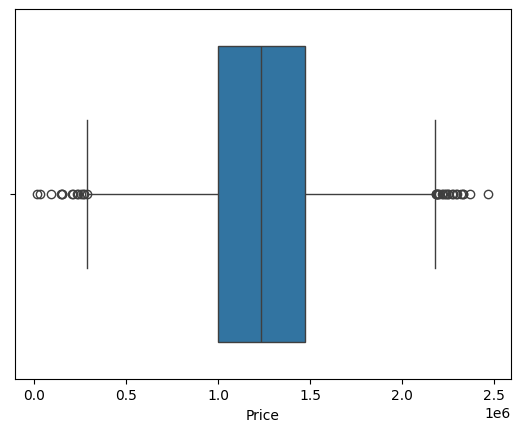

In [ ]:
sns.boxplot(x=df["Price"])
plt.show()

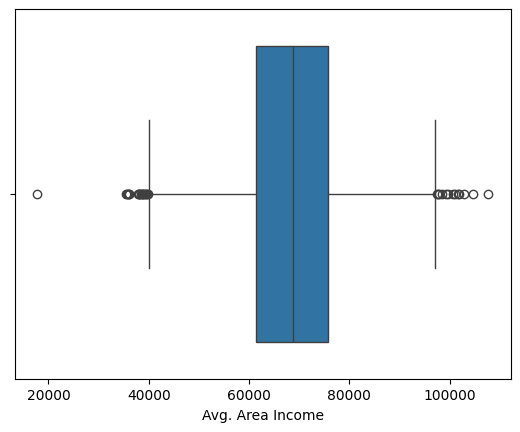

In [ ]:
sns.boxplot(x=df["Avg. Area Income"])
plt.show()

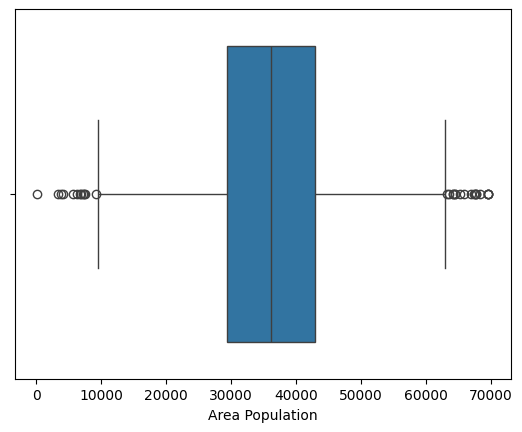

In [ ]:
sns.boxplot(x=df["Area Population"])
plt.show()

In [ ]:
Q1 = df["Price"].quantile(0.25)
Q3 = df["Price"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df = df[(df["Price"] >= lower) & (df["Price"] <= upper)]

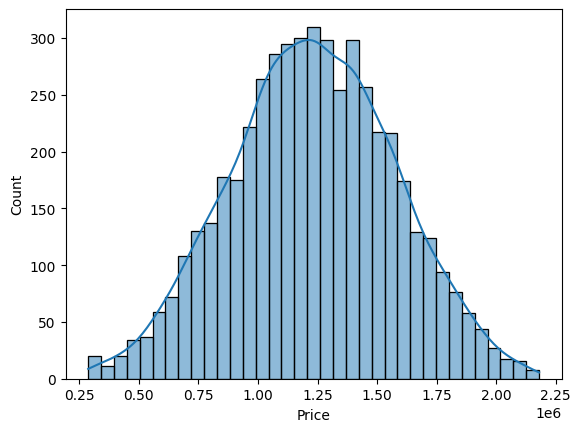

In [ ]:
sns.histplot(df["Price"], kde=True)
plt.show()

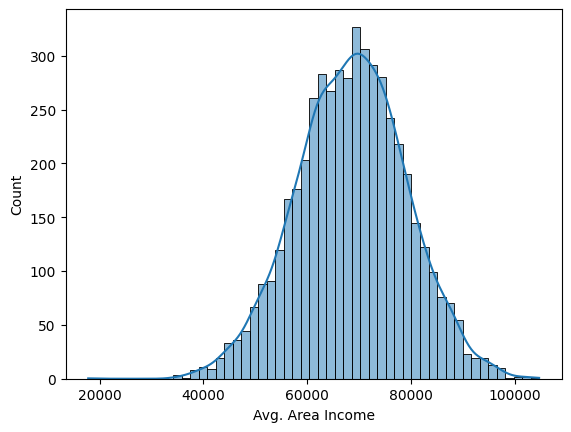

In [ ]:
sns.histplot(df["Avg. Area Income"], kde=True)
plt.show()

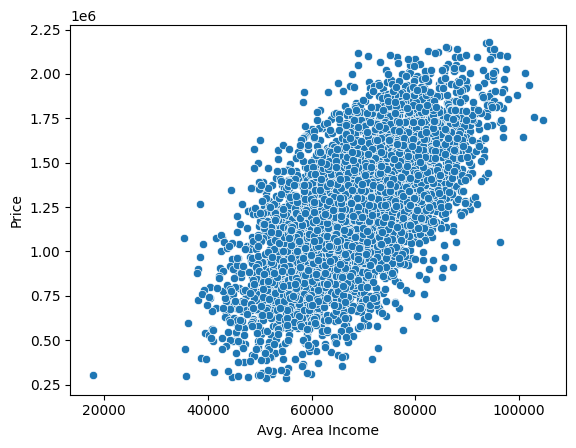

In [ ]:
sns.scatterplot(x="Avg. Area Income", y="Price", data=df)
plt.show()

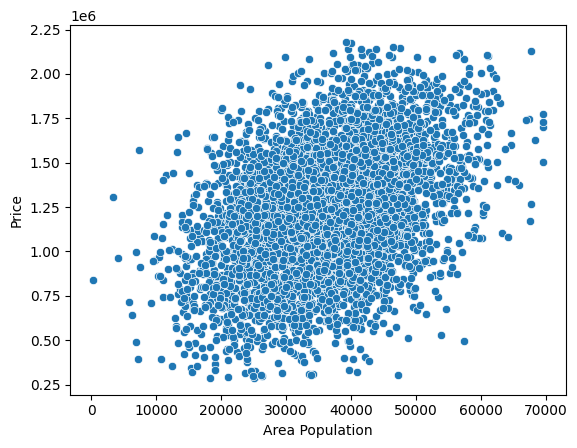

In [ ]:
sns.scatterplot(x="Area Population", y="Price", data=df)
plt.show()

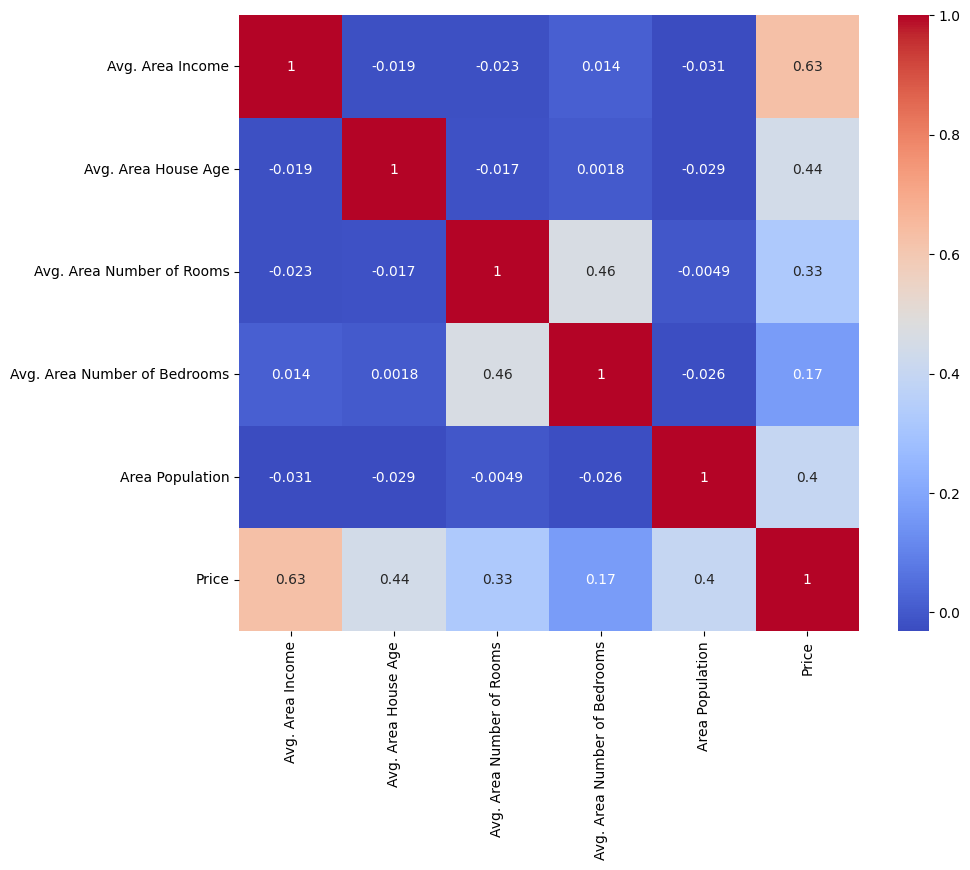

In [ ]:
plt.figure(figsize=(10,8))
numeric_df = df.select_dtypes(include=["number"])
sns.heatmap(numeric_df.corr(),
annot=True,
cmap = "coolwarm")
plt.show()

In [ ]:
print(df.shape)

(5000, 6)


In [ ]:
X = df.drop(["Price"], axis=1)
y = df["Price"]

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X = scaler.fit_transform(X)

In [ ]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

In [ ]:
print("Training Data:", x_train.shape)
print("Testing Data:", x_test.shape)

Training Data: (3972, 5)
Testing Data: (993, 5)



Simple Linear Regression



In [ ]:
x=df[['Avg. Area Income']]
y=df['Price']

In [ ]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=101)

In [ ]:
from sklearn.linear_model import LinearRegression
slr_model=LinearRegression()
slr_model.fit(x_train, y_train)

LinearRegression()

In [ ]:
y_pred=slr_model.predict(x_test)

In [ ]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

print("Simple Linear Regression")
print("------------------------")
print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))
print("Root Mean Squared Error:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

Simple Linear Regression
------------------------
Mean Absolute Error: 214381.53227575697
Mean Squared Error: 70973606008.72997
Root Mean Squared Error: 266408.71984364546
R2 Score: 0.38831542794888596


In [ ]:
print("Intercept:",slr_model.intercept_)
print("Slope:",slr_model.coef_[0])

Intercept: -179649.78619948635
Slope: 20.570701316847554


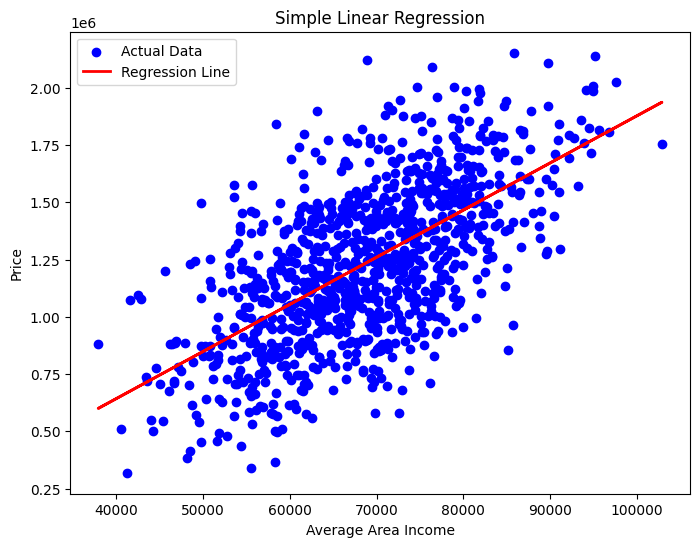

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(x_test,y_test,color='blue',label='Actual Data')
plt.plot(x_test,y_pred,color='red',linewidth=2,label='Regression Line')
plt.xlabel('Average Area Income')
plt.ylabel('Price')
plt.title('Simple Linear Regression')
plt.legend()
plt.show()

In [ ]:
income= float(input("Enter Average Area Income:"))
new_data=np.array([[income]])
prediction=slr_model.predict(new_data)
print("Predicted Price=${:.2f}".format(prediction[0]))

Enter Average Area Income:80000
Predicted Price=$1466006.32


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [ ]:
from sklearn.model_selection import GridSearchCV

Ridge Regression

In [ ]:

from sklearn.linear_model import Ridge
ridge = Ridge()

ridge.fit(x_train, y_train)

ridge_pred = ridge.predict(x_test)

print("Default Ridge Regression:", r2_score(y_test, ridge_pred))

Default Ridge Regression: 0.38831542794892593


In [ ]:
param_grid ={'alpha':[0.001,0.01,0.1,1,10,100]}
grid_ridge = GridSearchCV(estimator=Ridge(),param_grid=param_grid,scoring='r2',cv=5)
grid_ridge.fit(x_train,y_train)

print("Best Alpha:",grid_ridge.best_params_)
print(grid_ridge.best_score_)
best_ridge = grid_ridge.best_estimator_
ridge_pred = best_ridge.predict(x_test)

Best Alpha: {'alpha': 100}
0.3945472263614704


In [ ]:
print("MAE :",mean_absolute_error(y_test,ridge_pred))
print("MSE :",mean_squared_error(y_test,ridge_pred))
print("RMSE :", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

MAE : 214381.5322771852
MSE : 70973606008.26671
RMSE : 266408.71984364546
R2 Score: 0.38831542794888596
